# PUBG: Battlegrounds — Steam review analysis

Exploratory analysis of Steam reviews for **PUBG: Battlegrounds**: text preprocessing, word clouds,
word frequencies, VADER sentiment, and how sentiment relates to recommendations,
playtime and helpful votes.

Reviews are compared **before and after 2022-03-23** — PUBG becomes free to play.

| | |
|---|---|
| **Input** | `data/cleaned/PUBG_cleaned_reviews.csv` |
| **Tables** | `data/processed/PUBG/PUBG_*.csv` |
| **Figures** | `data/processed/PUBG/figures/*.png` |

## Setup

In [1]:
# Requirements: matplotlib, seaborn, nltk, scipy, wordcloud
# (install once with `%pip install matplotlib seaborn nltk scipy wordcloud` if needed)
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from nltk import pos_tag
from nltk.corpus import stopwords, wordnet
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from scipy import stats
from wordcloud import WordCloud

for resource in [
    "punkt",
    "punkt_tab",
    "stopwords",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng",
    "wordnet",
    "vader_lexicon",
]:
    nltk.download(resource, quiet=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 100)

### Configuration and helpers

In [2]:
NAME = "PUBG"
CUTOFF_DATE = "2022-03-23"  # PUBG becomes free to play
TEXT_COLUMN = "Processed_Review"
RECOMMENDATION_PALETTE = {"Recommended": "steelblue", "Not Recommended": "orange"}
RECOMMENDATION_ORDER = ["Recommended", "Not Recommended"]

# Paths work whether the notebook runs from `notebooks/` or the project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEANED_DIR = PROJECT_ROOT / "data" / "cleaned"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROCESSED_DIR / NAME  # every output of this notebook goes here
FIGURES_DIR = OUTPUT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = CLEANED_DIR / f"{NAME}_cleaned_reviews.csv"
PROCESSED_PATH = OUTPUT_DIR / f"{NAME}_cleaned_processed_reviews.csv"

In [3]:
def save_and_show(filename):
    """Save the current figure to FIGURES_DIR and display it."""
    plt.savefig(FIGURES_DIR / f"{filename}.png", dpi=150, bbox_inches="tight")
    plt.show()


def save_table(df, filename, **kwargs):
    """Save a table to OUTPUT_DIR as `<NAME>_<filename>.csv`."""
    df.to_csv(OUTPUT_DIR / f"{NAME}_{filename}.csv", **kwargs)


def show_wordcloud(text, title, filename):
    """Render, save and show a word cloud for the given text."""
    wordcloud = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        colormap="viridis",
        max_words=200,
        collocations=False,  # avoid duplicate phrases
    ).generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    save_and_show(filename)


def join_text(df, column=TEXT_COLUMN):
    """Concatenate all non-empty values of a text column into one string."""
    return df[column].dropna().astype(str).str.cat(sep=" ")


def split_by_cutoff(df, cutoff=CUTOFF_DATE):
    """Split reviews into those before and on/after the cutoff date."""
    cutoff = pd.Timestamp(cutoff)
    return df[df["Date"] < cutoff], df[df["Date"] >= cutoff]


def top_words(texts, n=20):
    """Return the `n` most frequent words in a series of texts."""
    all_text = " ".join(texts.dropna().astype(str))
    words = re.sub(r"[^\w\s]", "", all_text.lower()).split()
    freq_df = pd.DataFrame(Counter(words).items(), columns=["word", "frequency"])
    return freq_df.sort_values(by="frequency", ascending=False).head(n).reset_index(drop=True)


def plot_top_words(freq_df, title, filename):
    """Horizontal bar plot of word frequencies."""
    plt.figure(figsize=(12, 6))
    sns.barplot(data=freq_df, x="frequency", y="word", hue="word", palette="viridis", legend=False)
    plt.title(title)
    plt.xlabel("Frequency")
    plt.ylabel("Word")
    plt.tight_layout()
    save_and_show(filename)

## Load and preprocess data

Clean the `Hours Played` column, drop empty reviews and lemmatize the text. Game-specific
keywords are preserved and common variants are normalized (e.g. `cheater` → `cheat`).
The result is saved to `data/processed/PUBG/PUBG_cleaned_processed_reviews.csv`.

In [4]:
data = pd.read_csv(INPUT_PATH)
data["Hours Played"] = data["Hours Played"].replace(",", "", regex=True).astype(float)
data = data.dropna(subset=["Review"])

# Game-specific keywords kept as-is and variants normalized to one form
PRESERVE_KEYWORDS = {"pubg", "fps", "fpp", "tpp", "mm", "solo", "squad"}
REPLACEMENTS = {
    "cheating": "cheat",
    "cheater": "cheat",
    "cheated": "cheat",
    "hacker": "cheat",
    "hack": "cheat",
    "aimbot": "cheat",
    "wallhack": "cheat",
    "battlegrounds": "pubg",
}

EXTRA_STOP_WORDS = "o etc would could us the to of in it and this that for".split()
STOP_WORDS = set(stopwords.words("english")) | set(EXTRA_STOP_WORDS)
lemmatizer = WordNetLemmatizer()


def get_wordnet_pos(treebank_tag):
    """Map a Penn Treebank POS tag to the WordNet POS used by the lemmatizer."""
    pos_map = {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}
    return pos_map.get(treebank_tag[:1], wordnet.NOUN)


def preprocess_text(text):
    """Clean, tokenize and lemmatize a review while keeping domain keywords."""
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip().lower()

    tokens = []
    for word, pos in pos_tag(word_tokenize(text)):
        if word in PRESERVE_KEYWORDS:
            tokens.append(word)
        elif word not in STOP_WORDS and len(word) > 1 and not word.isnumeric():
            base = lemmatizer.lemmatize(word, get_wordnet_pos(pos))
            tokens.append(REPLACEMENTS.get(base, base))
    return " ".join(tokens)


data["Processed_Review"] = data["Review"].apply(preprocess_text)
data = data[data["Processed_Review"].str.strip() != ""].copy()
data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
data["Year"] = data["Date"].dt.year
data.to_csv(PROCESSED_PATH, index=False)

print(f"{len(data)} reviews from {data['Date'].min():%Y-%m-%d} to {data['Date'].max():%Y-%m-%d}")
data[["Date", "Review", "Processed_Review", "Recommendation"]].head()

744 reviews from 2017-03-23 to 2024-12-21


,Date,Review,Processed_Review,Recommendation
0,2020-06-25,"After almost 1000 hours of playing, it's time for me to voice my thoughts. I've owned and played...",almost hour play time voice thought own play pubg since official release steam good bad ugly two...,Not Recommended
1,2020-01-17,"After 2 years and 2,200 hours of gameplay, I was Permanently Banned from PUBG without any reason...",year hour gameplay permanently ban pubg without reasoning provide purchase every event pas even ...,Not Recommended
2,2020-04-26,"3 years and 3,500 hours of gameplay and this game is still a joke. Very clunky, glitches, bugs, ...",year hour gameplay game still joke clunky glitch bug fps drop desync name still live one thing s...,Not Recommended
3,2021-04-22,"AS OF 2024, Reporting system is shockers. TEAMING in public is now a thing! Radar hack is everyw...",reporting system shocker team public thing radar cheat everywhere especially rank four prove you...,Not Recommended
4,2021-12-10,This game will be free from January 12 2022!,game free january,Recommended


## Tokenization and vocabulary filtering

Tokens occurring fewer than `min_word_freq` times are removed. The filtered documents
and the remaining metadata are saved to `data/processed/<NAME>/` for later topic modelling.

In [5]:
data["Tokenized_Review"] = data["Processed_Review"].apply(word_tokenize)


def build_vocab(tokenized_reviews, min_word_freq=2):
    """Return the set of tokens occurring at least `min_word_freq` times."""
    counts = Counter(token for tokens in tokenized_reviews for token in tokens)
    return {word for word, count in counts.items() if count >= min_word_freq}


min_word_freq = 2
vocab = build_vocab(data["Tokenized_Review"], min_word_freq)

data["Filtered_Review"] = data["Tokenized_Review"].apply(
    lambda tokens: [word for word in tokens if word in vocab]
)
documents = data["Filtered_Review"].apply(" ".join)
metadata = data.drop(columns=["Review", "Processed_Review", "Tokenized_Review", "Filtered_Review"])

save_table(documents, "documents", index=False, header=["Documents"])
save_table(metadata, "metadata", index=False)

print(f"Vocabulary size: {len(vocab)}")
print(f"Sample vocabulary: {sorted(vocab)[:15]}")
documents.head().to_frame("Document")

Vocabulary size: 3064
Sample vocabulary: ['100hrs', '100ms', '1080p', '16gb', '1st', '1v1', '200hrs', '200m', '20hz', '20k', '2gb', '2k', '2nd', '3rd', '4k']


,Document
0,almost hour play time voice thought own play pubg since official release steam good bad ugly two...
1,year hour gameplay permanently ban pubg without provide purchase every event pas even purchase g...
2,year hour gameplay game still joke clunky glitch bug fps drop desync name still live one thing s...
3,reporting system team public thing radar cheat everywhere especially rank four prove youtube vid...
4,game free january


## Word clouds

### All reviews

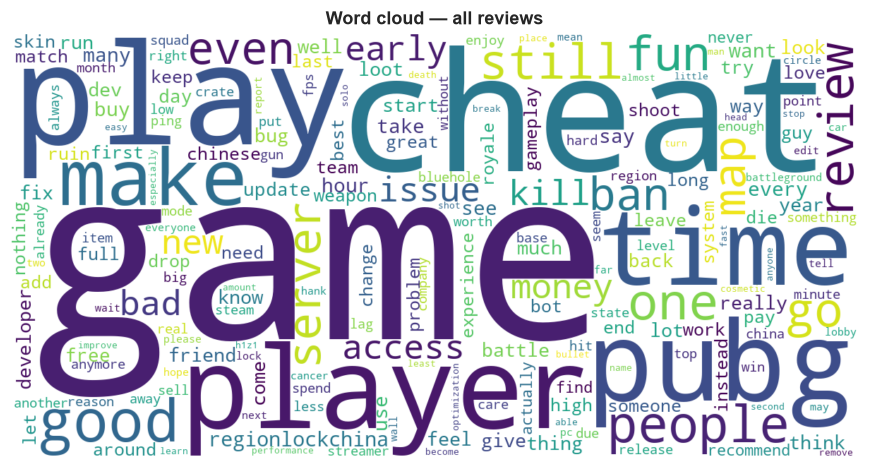

In [6]:
# Reload the processed reviews saved above
data = pd.read_csv(PROCESSED_PATH, parse_dates=["Date"])
show_wordcloud(join_text(data), "Word cloud — all reviews", "wordcloud_all")

### Before vs after 2022-03-23

PUBG becomes free to play.

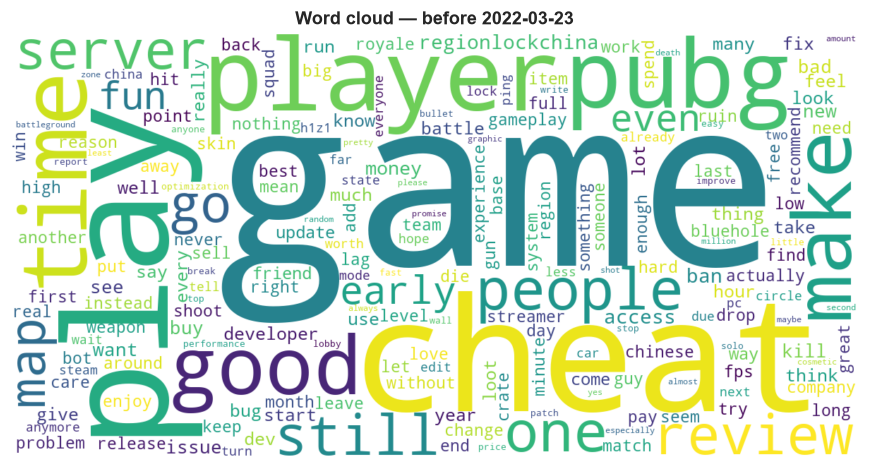

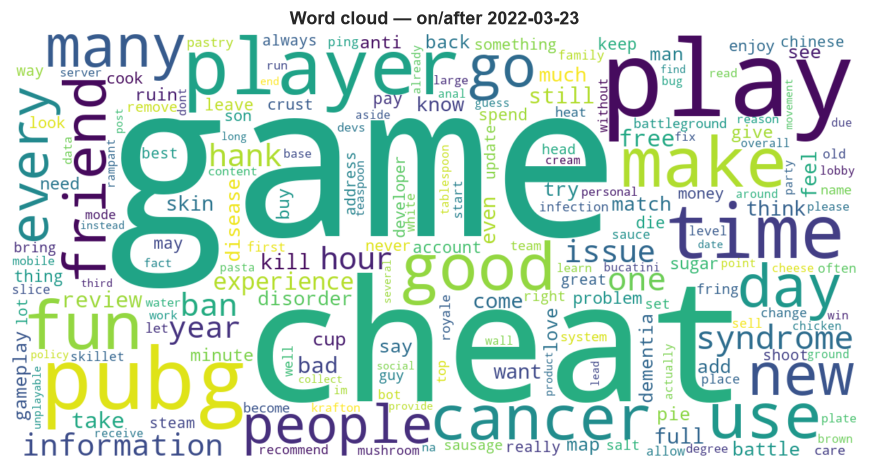

In [7]:
before_df, after_df = split_by_cutoff(data)

show_wordcloud(join_text(before_df), f"Word cloud — before {CUTOFF_DATE}", "wordcloud_before")
show_wordcloud(join_text(after_df), f"Word cloud — on/after {CUTOFF_DATE}", "wordcloud_after")

## Word frequencies

### All reviews

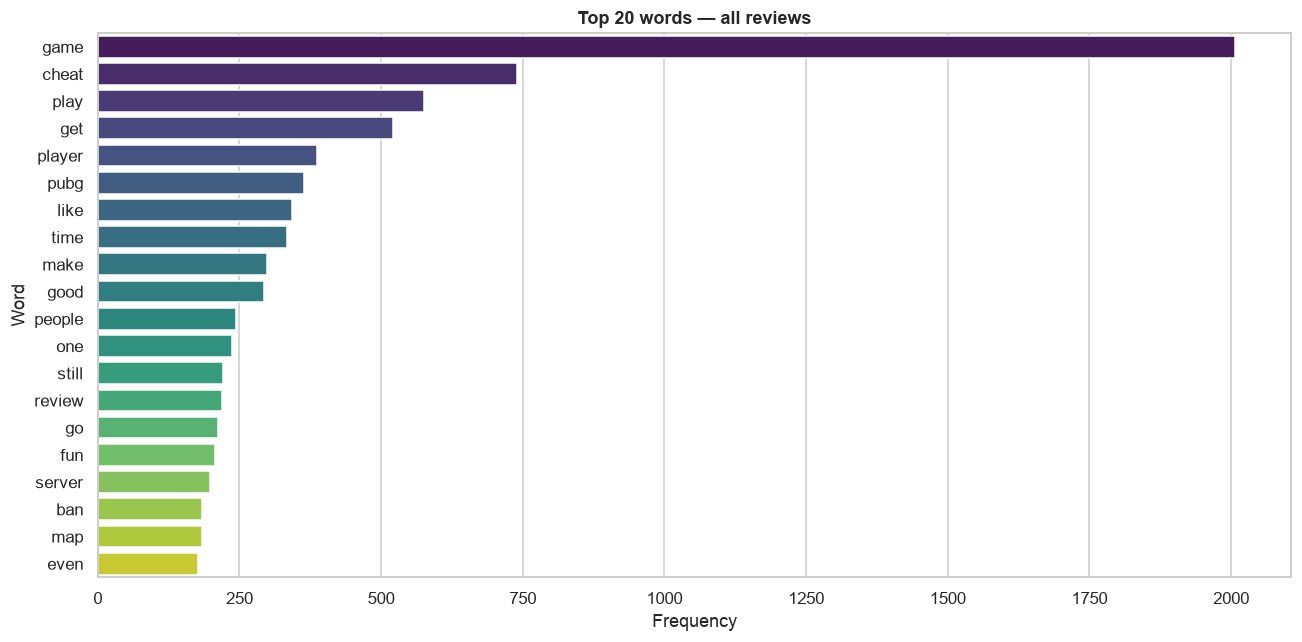

In [8]:
freq_df = top_words(data[TEXT_COLUMN])
save_table(freq_df, "top_words_all", index=False)
plot_top_words(freq_df, "Top 20 words — all reviews", "top_words_all")

### Before vs after 2022-03-23

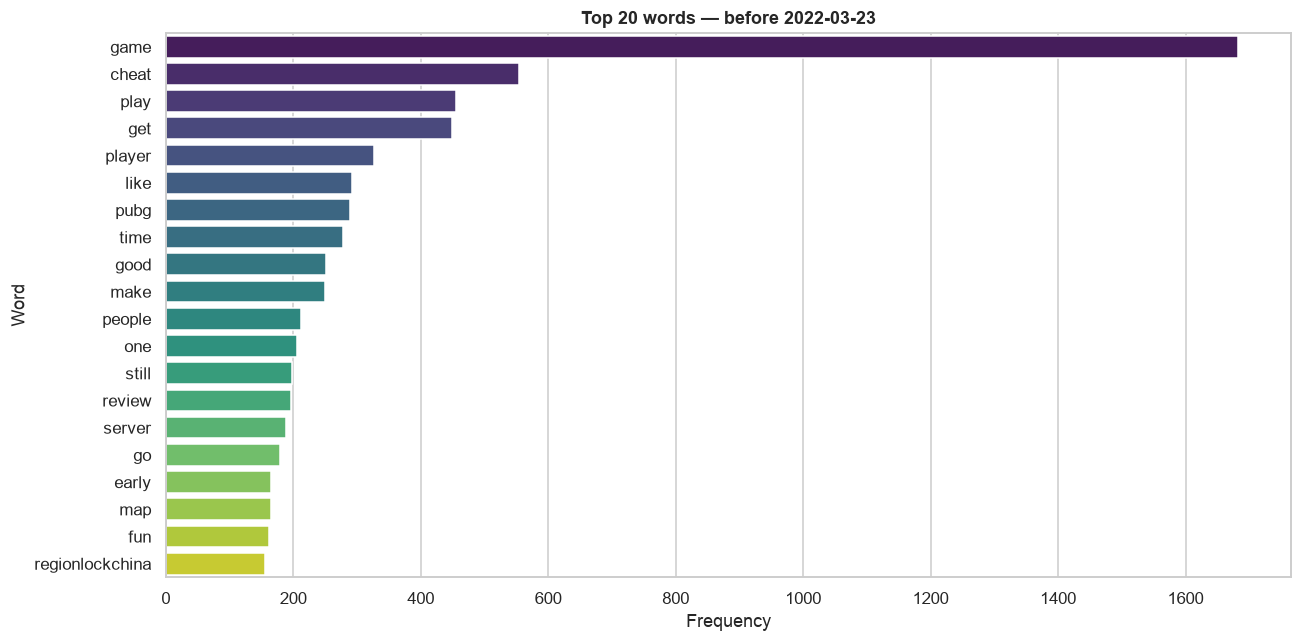

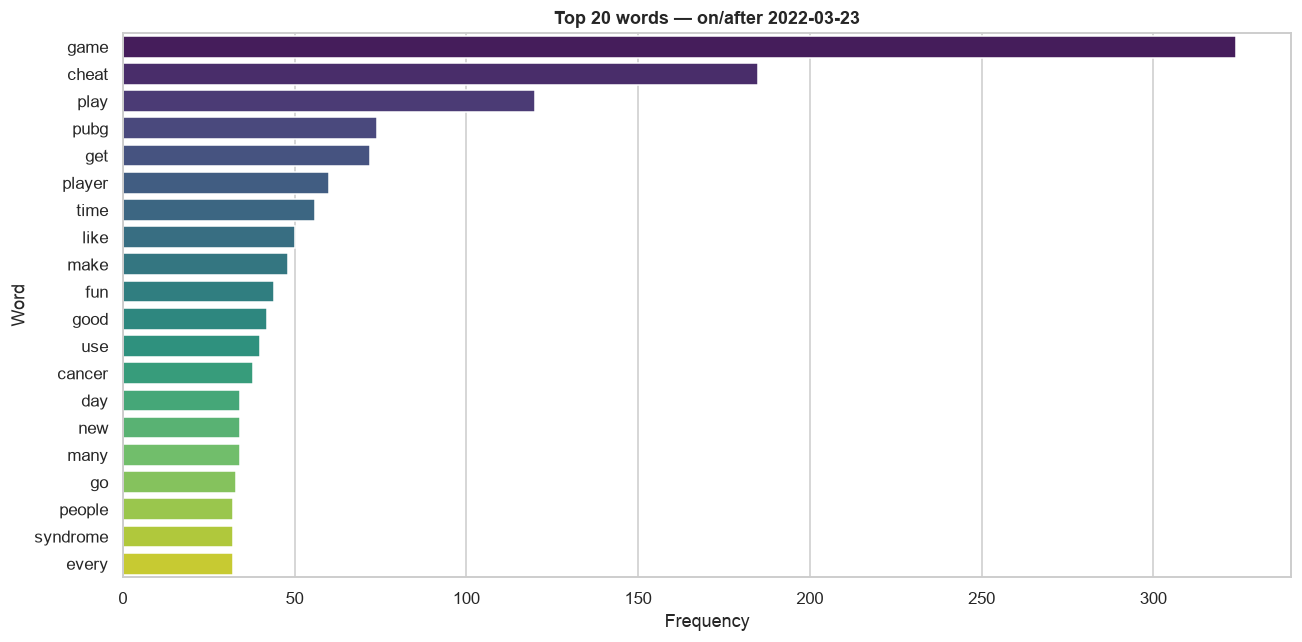

before            on/after          
               word frequency      word frequency
0              game      1682      game       324
1             cheat       554     cheat       185
2              play       455      play       120
3               get       449      pubg        74
4            player       326       get        72
5              like       292    player        60
6              pubg       289      time        56
7              time       278      like        50
8              good       252      make        48
9              make       250       fun        44
10           people       212      good        42
11              one       206       use        40
12            still       198    cancer        38
13           review       197       day        34
14           server       189       new        34
15               go       179      many        34
16            early       165        go        33
17              map       165    people        32
18              fun       162  syndrome        32
19  regionlockchina       156     every        32

In [9]:
before_df, after_df = split_by_cutoff(data)
freq_before = top_words(before_df[TEXT_COLUMN])
freq_after = top_words(after_df[TEXT_COLUMN])

save_table(freq_before, "top_words_before", index=False)
save_table(freq_after, "top_words_after", index=False)
plot_top_words(freq_before, f"Top 20 words — before {CUTOFF_DATE}", "top_words_before")
plot_top_words(freq_after, f"Top 20 words — on/after {CUTOFF_DATE}", "top_words_after")

# Side-by-side comparison
pd.concat({"before": freq_before, "on/after": freq_after}, axis=1)

## Sentiment analysis (VADER)

VADER assigns each review a compound score in `[-1, 1]`:

| Score | Category |
|---|---|
| ≥ 0.05 | Positive |
| ≤ -0.05 | Negative |
| otherwise | Neutral |

The scored reviews are saved to `data/processed/PUBG/PUBG_sentiment.csv`.

In [10]:
sia = SentimentIntensityAnalyzer()


def get_sentiment_category(score):
    """Map a VADER compound score to Positive / Neutral / Negative."""
    if score >= 0.05:
        return "Positive"
    if score <= -0.05:
        return "Negative"
    return "Neutral"


data = data.dropna(subset=[TEXT_COLUMN]).copy()
data["sentiment_score"] = (
    data[TEXT_COLUMN].astype(str).apply(lambda text: sia.polarity_scores(text)["compound"])
)
data["sentiment_category"] = data["sentiment_score"].apply(get_sentiment_category)
save_table(data, "sentiment", index=False)

before_df, after_df = split_by_cutoff(data)
summary = pd.DataFrame(
    {
        "reviews": [len(before_df), len(after_df)],
        "mean_score": [before_df["sentiment_score"].mean(), after_df["sentiment_score"].mean()],
        "positive_share": [
            (before_df["sentiment_category"] == "Positive").mean(),
            (after_df["sentiment_category"] == "Positive").mean(),
        ],
    },
    index=[f"before {CUTOFF_DATE}", f"on/after {CUTOFF_DATE}"],
).round(3)
save_table(summary, "sentiment_summary")
summary

,reviews,mean_score,positive_share
before 2022-03-23,538,0.036,0.467
on/after 2022-03-23,206,0.043,0.519


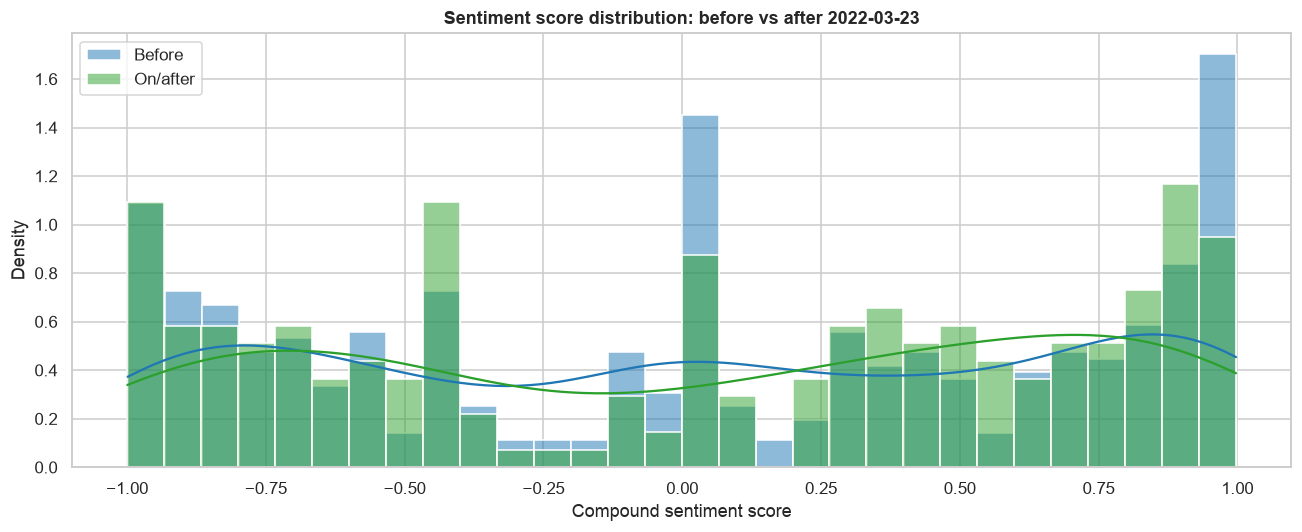

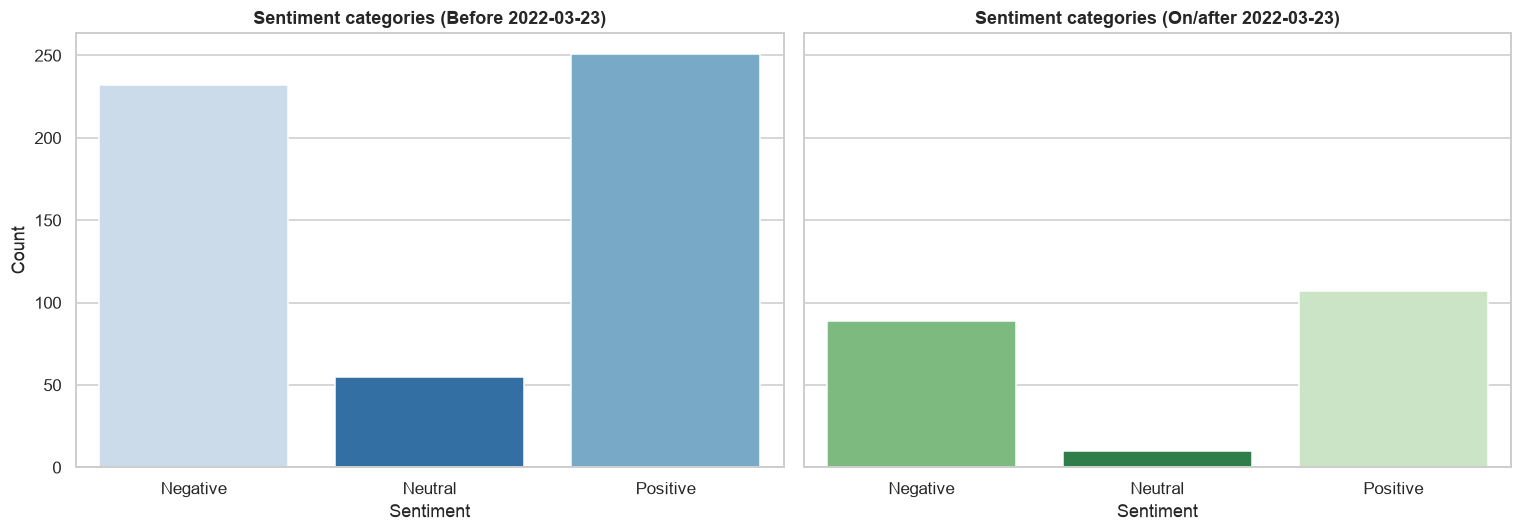

In [11]:
# Sentiment score distribution
plt.figure(figsize=(12, 5))
sns.histplot(
    before_df["sentiment_score"],
    color="tab:blue",
    kde=True,
    label="Before",
    bins=30,
    stat="density",
)
sns.histplot(
    after_df["sentiment_score"],
    color="tab:green",
    kde=True,
    label="On/after",
    bins=30,
    stat="density",
)
plt.title(f"Sentiment score distribution: before vs after {CUTOFF_DATE}")
plt.xlabel("Compound sentiment score")
plt.legend()
plt.tight_layout()
save_and_show("sentiment_distribution")

# Sentiment category counts
CATEGORY_ORDER = ["Negative", "Neutral", "Positive"]
fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, subset, label, palette in [
    (axs[0], before_df, "Before", "Blues"),
    (axs[1], after_df, "On/after", "Greens"),
]:
    sns.countplot(
        data=subset,
        x="sentiment_category",
        hue="sentiment_category",
        order=CATEGORY_ORDER,
        palette=palette,
        legend=False,
        ax=ax,
    )
    ax.set_title(f"Sentiment categories ({label} {CUTOFF_DATE})")
    ax.set_xlabel("Sentiment")
axs[0].set_ylabel("Count")
plt.tight_layout()
save_and_show("sentiment_categories")

### Distribution fits

Normal, Laplace and rescaled Beta distributions are fitted to the sentiment scores to
see which shape best describes each period.

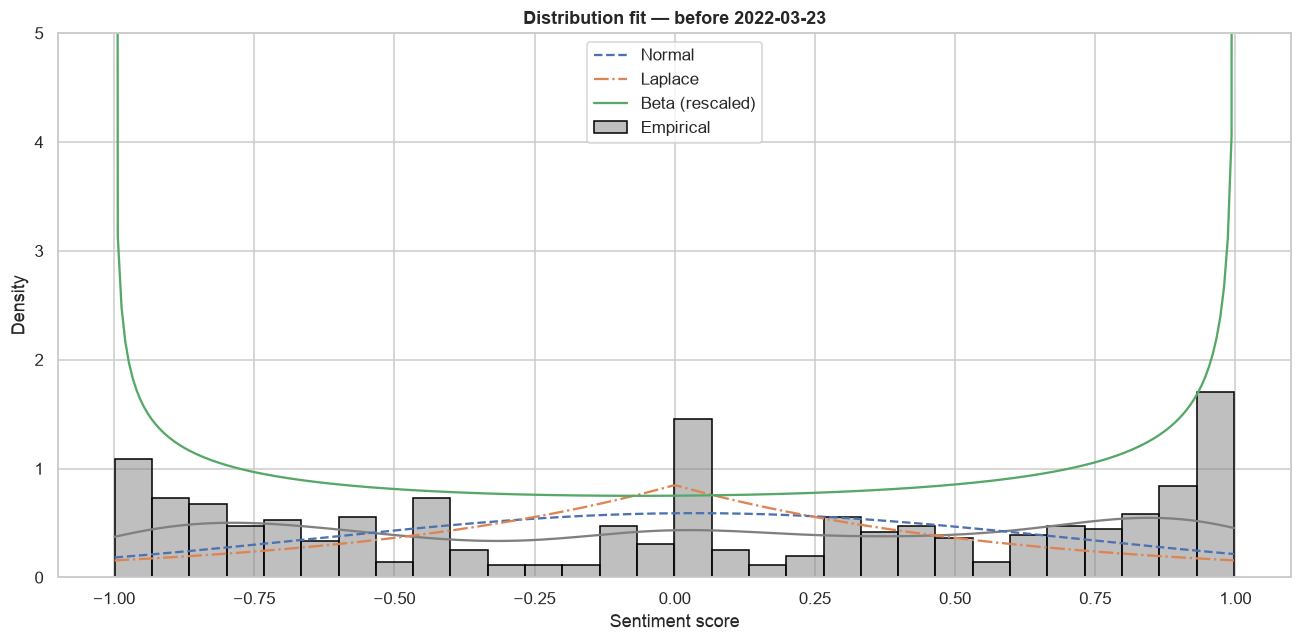

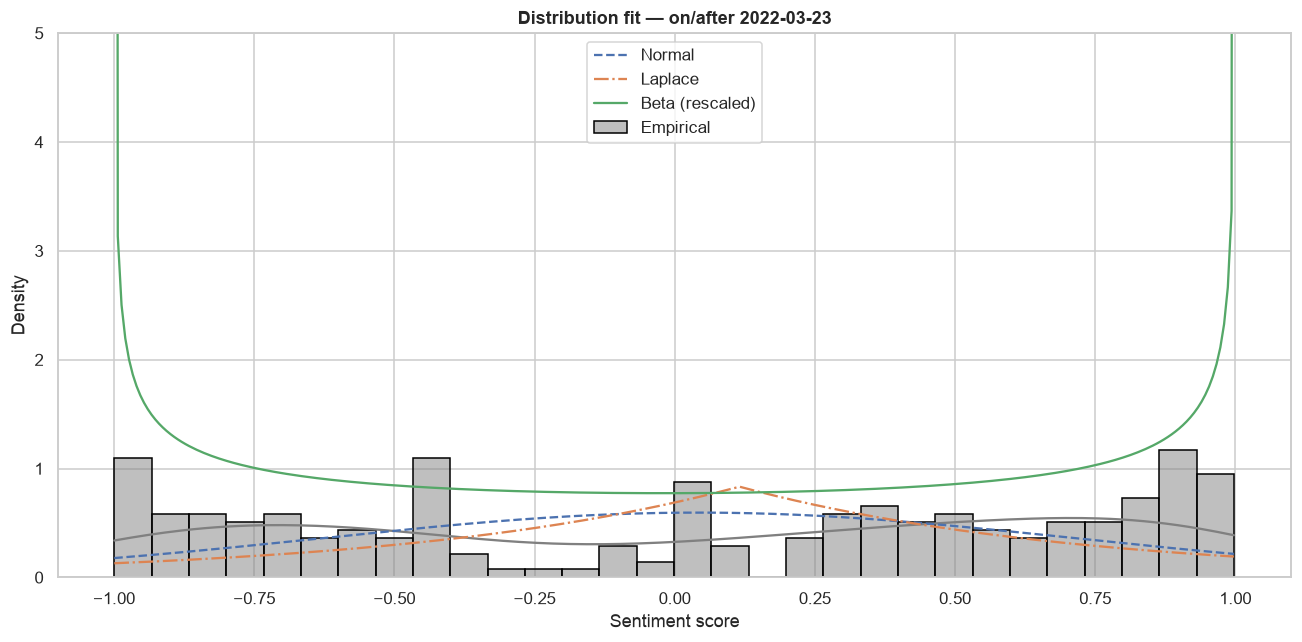

In [12]:
def compare_distributions(sample, title, filename):
    """Overlay Normal, Laplace and rescaled Beta fits on the empirical distribution."""
    plt.figure(figsize=(12, 6))
    sns.histplot(
        sample,
        kde=True,
        stat="density",
        bins=30,
        label="Empirical",
        color="gray",
        edgecolor="black",
    )
    x = np.linspace(sample.min(), sample.max(), 300)

    # Normal
    plt.plot(x, stats.norm.pdf(x, sample.mean(), sample.std()), label="Normal", linestyle="--")

    # Laplace
    loc, scale = stats.laplace.fit(sample)
    plt.plot(x, stats.laplace.pdf(x, loc, scale), label="Laplace", linestyle="-.")

    # Beta, rescaled from [-1, 1] to (0, 1) and back
    sample_beta = np.clip((sample + 1) / 2, 1e-6, 1 - 1e-6)
    a_beta, b_beta, _, _ = stats.beta.fit(sample_beta, floc=0, fscale=1)
    x_beta = np.linspace(1e-6, 1 - 1e-6, 300)
    plt.plot(x_beta * 2 - 1, stats.beta.pdf(x_beta, a_beta, b_beta), label="Beta (rescaled)")

    plt.title(f"Distribution fit — {title}")
    plt.xlabel("Sentiment score")
    plt.ylabel("Density")
    plt.ylim(0, 5)  # keep the tall peak at 0 from hiding the fits
    plt.legend()
    plt.tight_layout()
    save_and_show(filename)


compare_distributions(
    before_df["sentiment_score"], f"before {CUTOFF_DATE}", "distribution_fit_before"
)
compare_distributions(
    after_df["sentiment_score"], f"on/after {CUTOFF_DATE}", "distribution_fit_after"
)

### Average sentiment per year

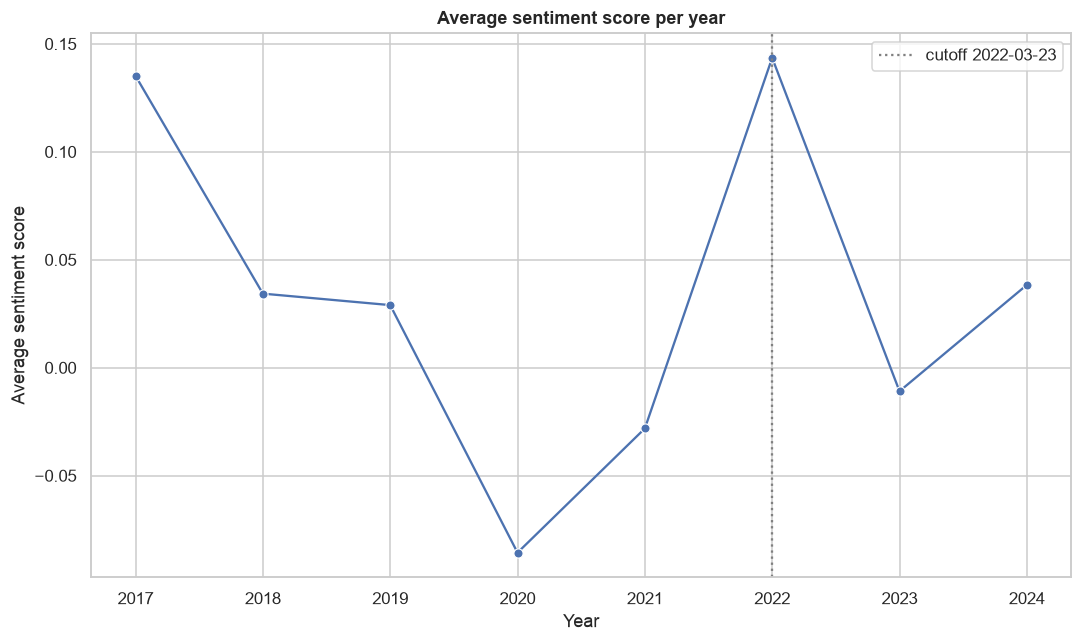

,Year,mean,count
0,2017,0.135169,125
1,2018,0.034286,140
2,2019,0.028972,67
3,2020,-0.085705,86
4,2021,-0.028170,86
5,2022,0.143507,88
6,2023,-0.010926,84
7,2024,0.038322,68


In [13]:
yearly_sentiment = data.groupby("Year")["sentiment_score"].agg(["mean", "count"]).reset_index()
yearly_sentiment["Year"] = yearly_sentiment["Year"].astype(int)
save_table(yearly_sentiment, "yearly_sentiment", index=False)

plt.figure(figsize=(10, 6))
sns.lineplot(data=yearly_sentiment, x="Year", y="mean", marker="o")
plt.axvline(
    pd.Timestamp(CUTOFF_DATE).year, color="gray", linestyle=":", label=f"cutoff {CUTOFF_DATE}"
)
plt.title("Average sentiment score per year")
plt.xlabel("Year")
plt.ylabel("Average sentiment score")
plt.xticks(yearly_sentiment["Year"])
plt.legend()
plt.tight_layout()
save_and_show("yearly_sentiment")

yearly_sentiment

### Word clouds per year

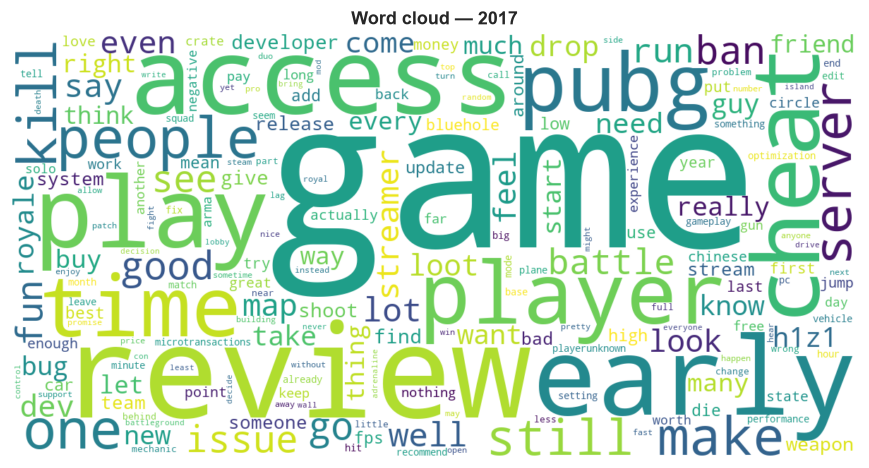

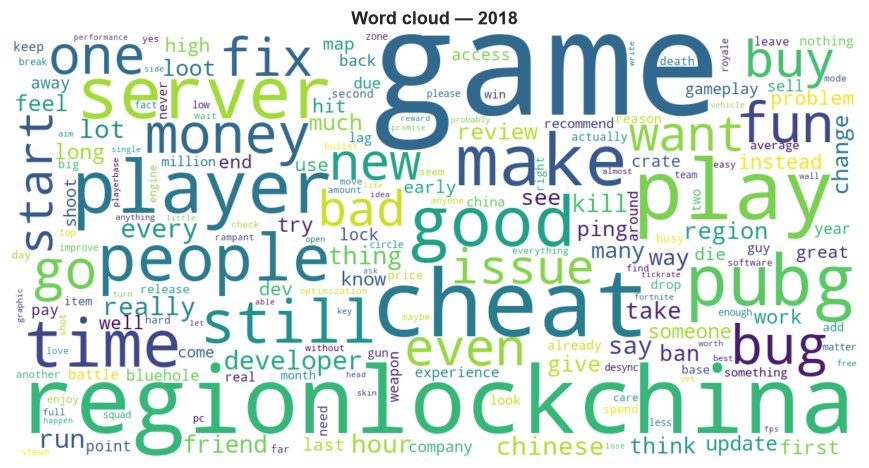

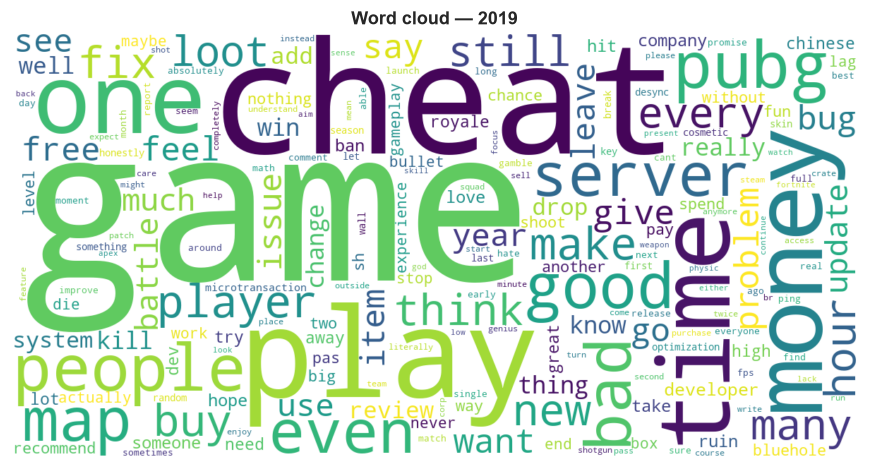

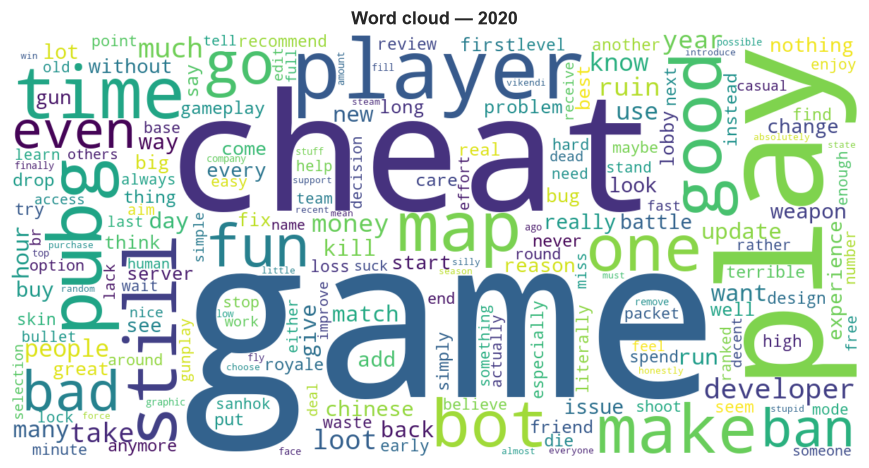

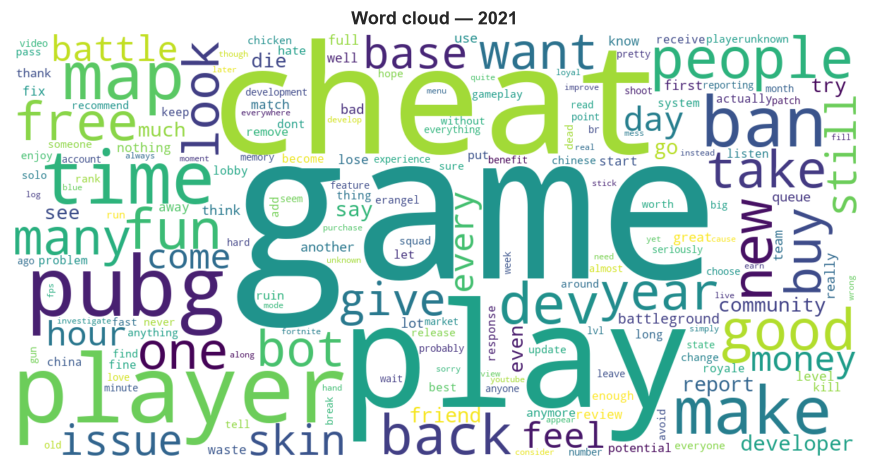

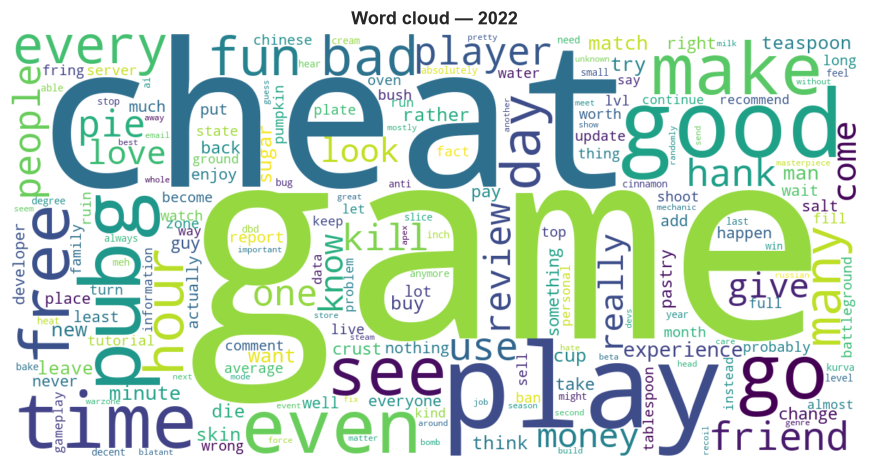

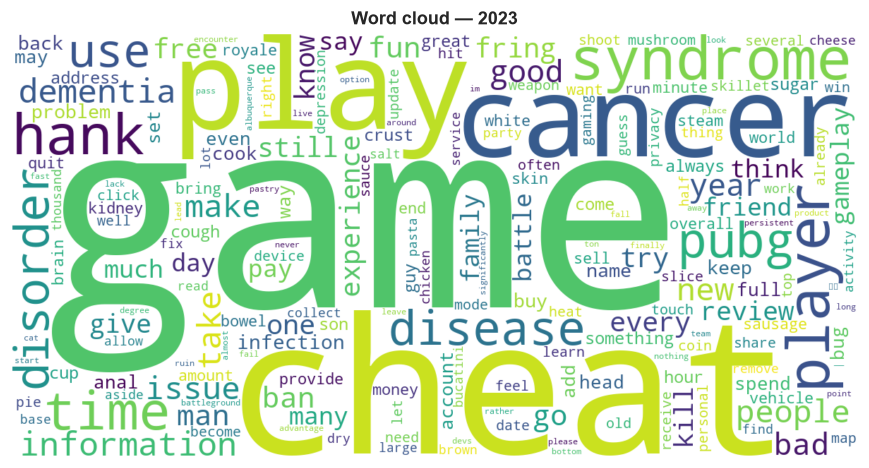

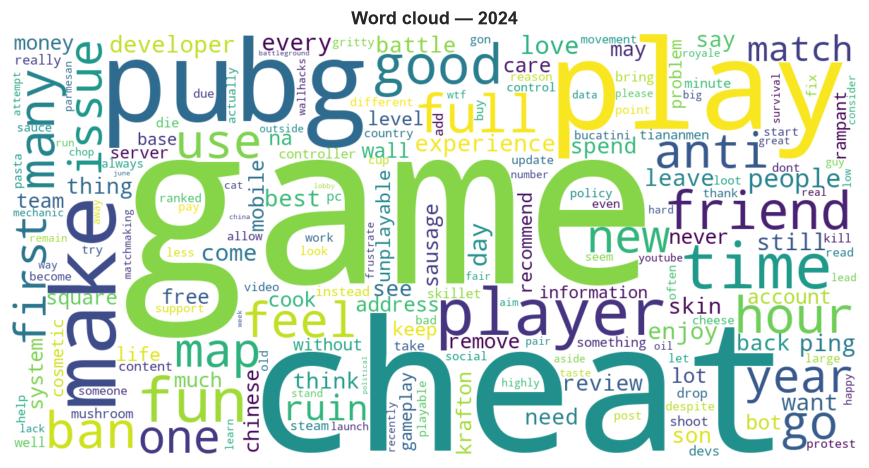

In [14]:
for year in sorted(data["Year"].dropna().astype(int).unique()):
    show_wordcloud(
        join_text(data[data["Year"] == year]), f"Word cloud — {year}", f"wordcloud_{year}"
    )

## Sentiment vs user recommendation

Does the text sentiment agree with whether the user recommended the game?

`Recommendation` is binary while the sentiment category has three levels, so a count
plot alone can be misleading. A box plot of the sentiment score per recommendation shows
the distributions directly, and may reveal whether *Neutral* reviews lean towards
*Recommended* — which would allow treating sentiment as a binary variable.

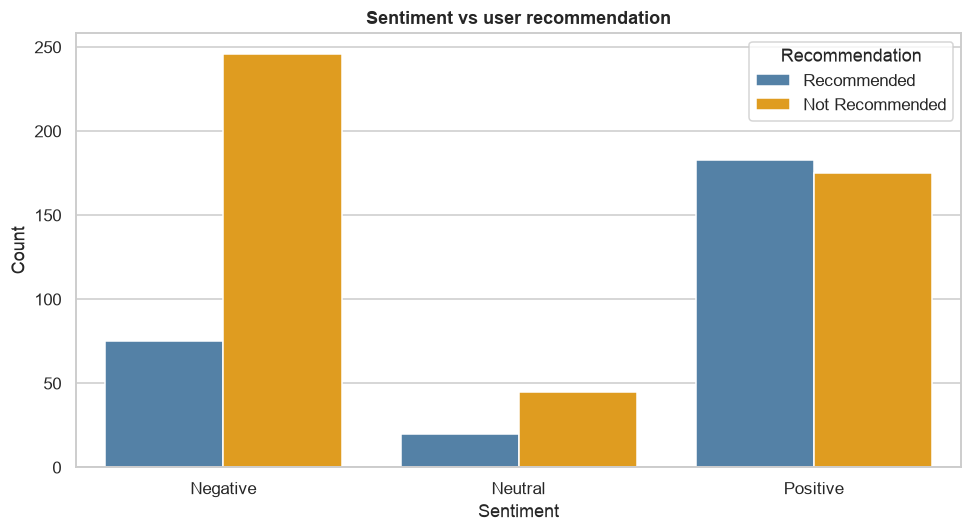

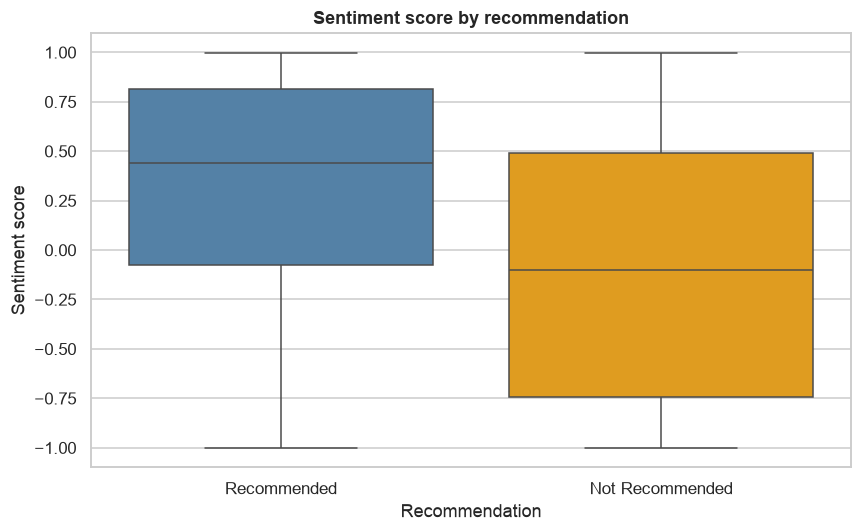

Missing 'Recommendation' values: 0


Recommendation,Not Recommended,Recommended,All
sentiment_category,,,
Negative,246,75,321
Neutral,45,20,65
Positive,175,183,358
All,466,278,744


In [15]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=data,
    x="sentiment_category",
    hue="Recommendation",
    order=CATEGORY_ORDER,
    hue_order=RECOMMENDATION_ORDER,
    palette=RECOMMENDATION_PALETTE,
)
plt.title("Sentiment vs user recommendation")
plt.ylabel("Count")
plt.xlabel("Sentiment")
plt.tight_layout()
save_and_show("sentiment_vs_recommendation")

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=data,
    x="Recommendation",
    y="sentiment_score",
    hue="Recommendation",
    order=RECOMMENDATION_ORDER,
    palette=RECOMMENDATION_PALETTE,
    legend=False,
)
plt.title("Sentiment score by recommendation")
plt.ylabel("Sentiment score")
plt.tight_layout()
save_and_show("sentiment_by_recommendation")

print(f"Missing 'Recommendation' values: {data['Recommendation'].isna().sum()}")
crosstab = pd.crosstab(data["sentiment_category"], data["Recommendation"], margins=True)
save_table(crosstab, "sentiment_vs_recommendation")
crosstab

## Sentiment, recommendation, hours played and helpful votes

Metadata such as **Hours Played** and **Helpful Votes** adds context to the review text.

**Variables**

- **Sentiment score** – text sentiment
- **Recommendation** – positive / negative game recommendation
- **Hours played** – time spent in the game, an indicator of engagement
- **Helpful votes** – number of users who found the review helpful

**Why metadata?**

- Many hours combined with negative sentiment may indicate valid, constructive criticism.
- Helpful votes reflect the perceived quality of a review; many votes suggest a more
  influential opinion.

**Research questions**

1. Do highly engaged users (many hours played) express more polarized sentiment?
2. Are reviews with few helpful votes more neutral or noisy?
3. Do *Not Recommended* reviews with many helpful votes form separate clusters?

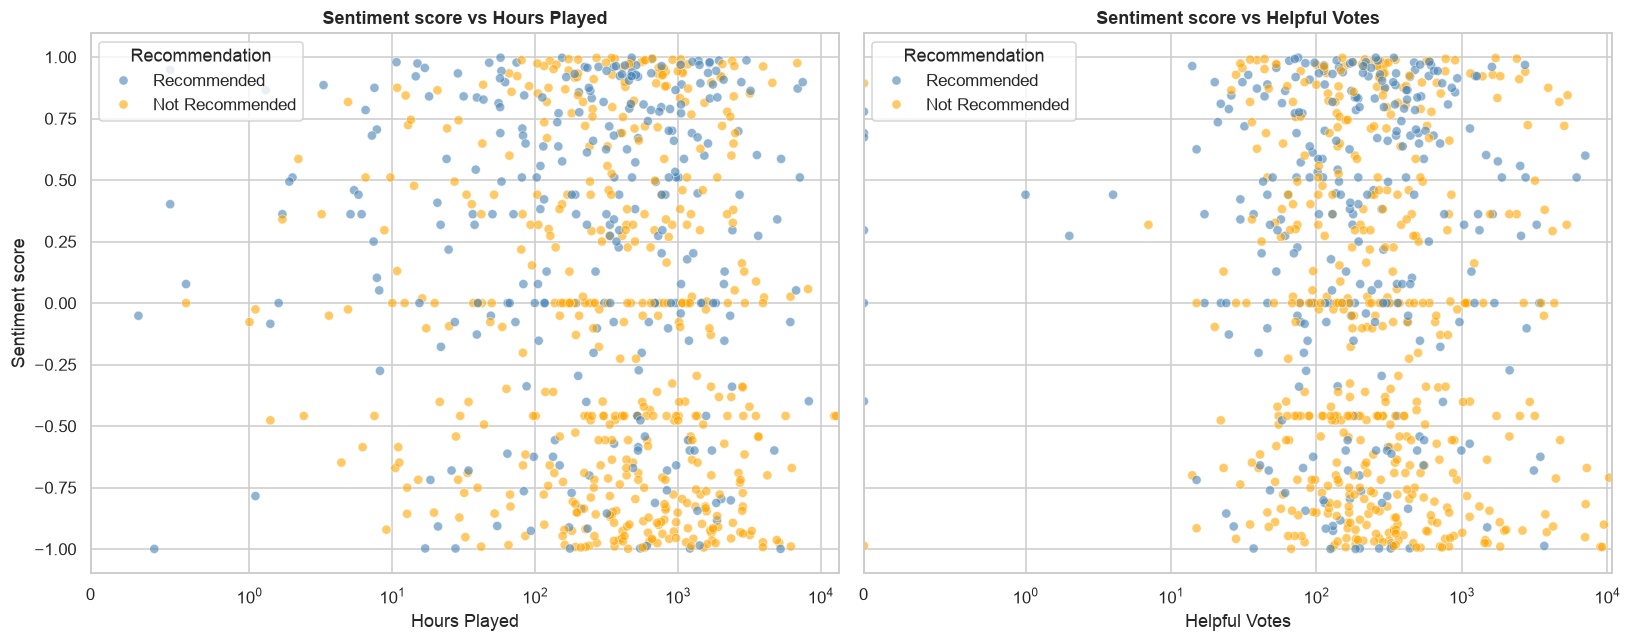

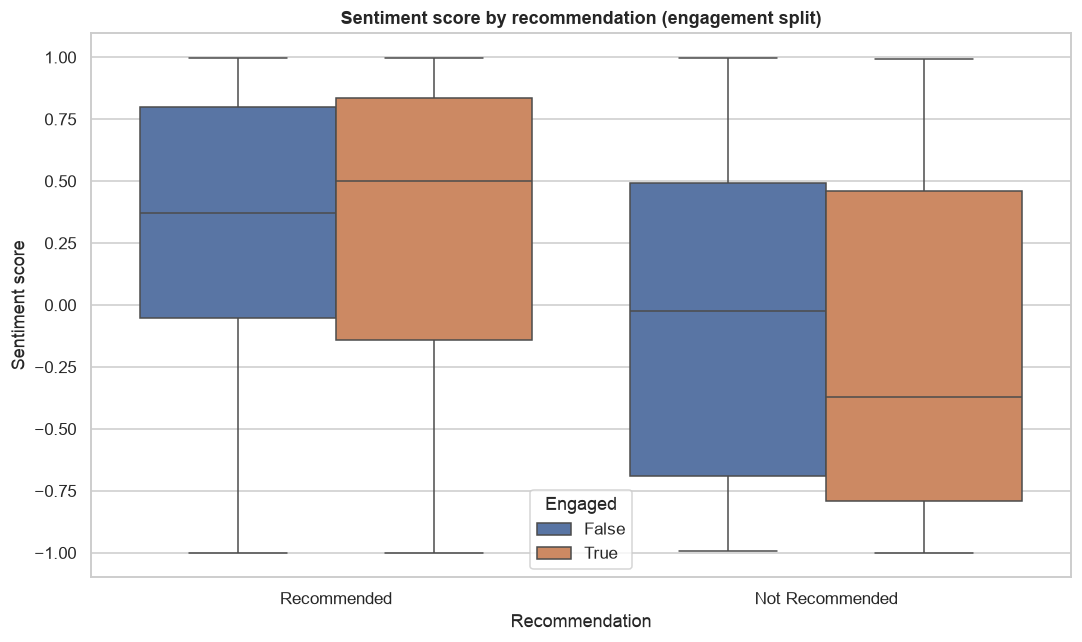

In [16]:
NUMERIC_COLUMNS = ["Hours Played", "Helpful Votes", "sentiment_score"]
METRICS = ["Hours Played", "Helpful Votes"]
PERIODS = ["Before", "After"]

df = data.copy()
df[NUMERIC_COLUMNS] = df[NUMERIC_COLUMNS].apply(pd.to_numeric, errors="coerce")
df["Period"] = np.where(df["Date"] < pd.Timestamp(CUTOFF_DATE), "Before", "After")

df_clean = df.dropna(subset=[*NUMERIC_COLUMNS, "Recommendation"]).copy()
df_clean["Engaged"] = df_clean["Hours Played"] > df_clean["Hours Played"].median()

# Sentiment vs hours played / helpful votes (log scale handles skew and outliers)
fig, axs = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, metric in zip(axs, METRICS):
    sns.scatterplot(
        data=df_clean,
        x=metric,
        y="sentiment_score",
        hue="Recommendation",
        hue_order=RECOMMENDATION_ORDER,
        palette=RECOMMENDATION_PALETTE,
        alpha=0.6,
        ax=ax,
    )
    ax.set_xscale("symlog", linthresh=1)  # log scale that keeps 0 values
    ax.set_xlim(left=0)
    ax.set_title(f"Sentiment score vs {metric}")
    ax.set_ylabel("Sentiment score")
plt.tight_layout()
save_and_show("sentiment_vs_metadata")

# Sentiment by recommendation, split by engagement (above-median hours played)
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_clean,
    x="Recommendation",
    y="sentiment_score",
    hue="Engaged",
    order=RECOMMENDATION_ORDER,
)
plt.title("Sentiment score by recommendation (engagement split)")
plt.ylabel("Sentiment score")
plt.tight_layout()
save_and_show("sentiment_by_engagement")

### Before vs after 2022-03-23

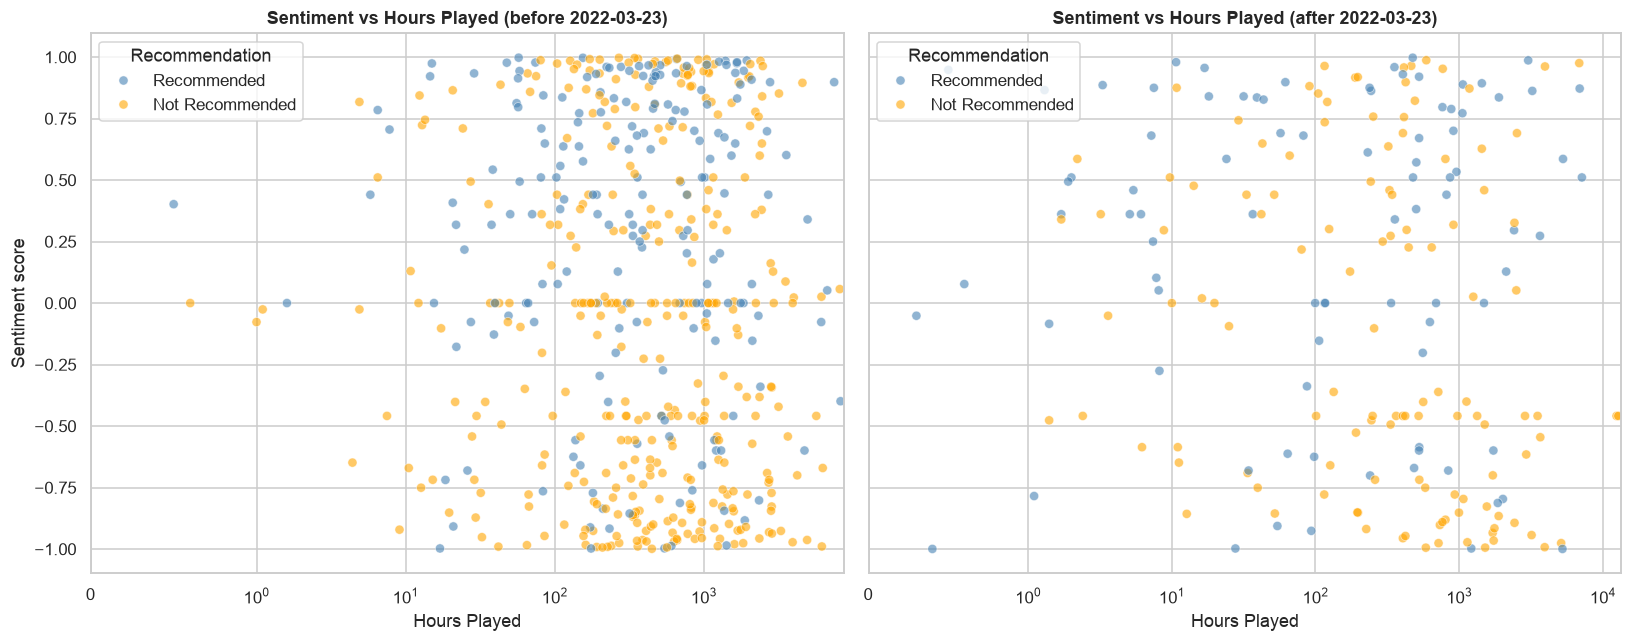

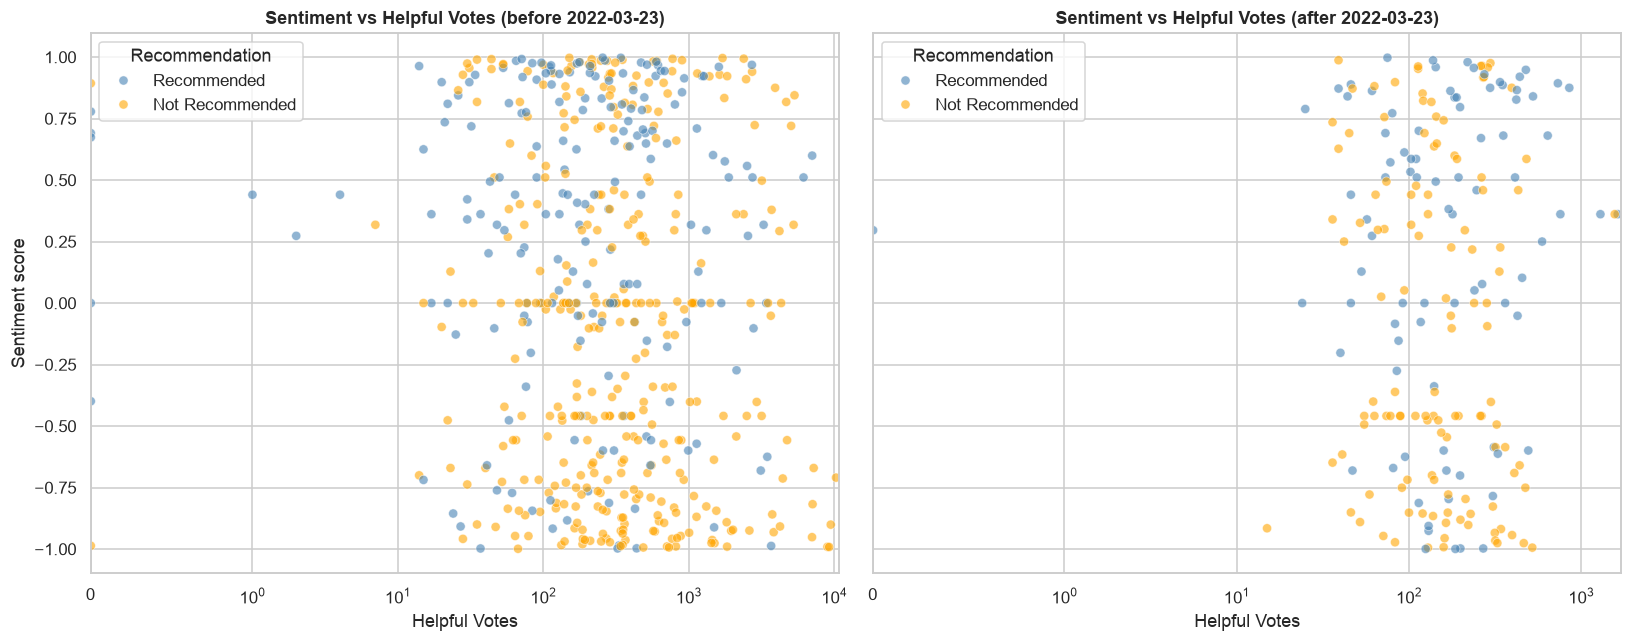

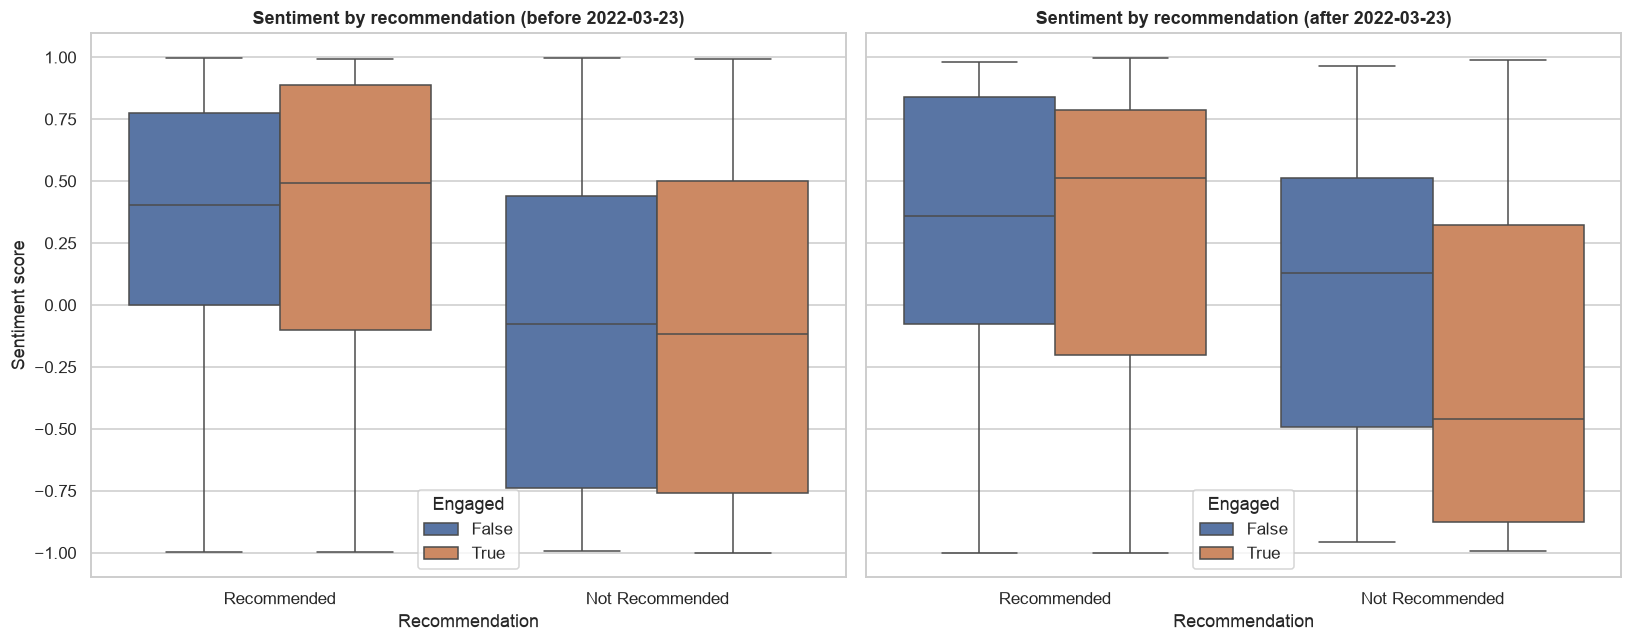

In [17]:
# Sentiment vs hours played / helpful votes, per period
for metric in METRICS:
    fig, axs = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
    for ax, period in zip(axs, PERIODS):
        sns.scatterplot(
            data=df_clean[df_clean["Period"] == period],
            x=metric,
            y="sentiment_score",
            hue="Recommendation",
            hue_order=RECOMMENDATION_ORDER,
            palette=RECOMMENDATION_PALETTE,
            alpha=0.6,
            ax=ax,
        )
        ax.set_xscale("symlog", linthresh=1)  # log scale that keeps 0 values
        ax.set_xlim(left=0)
        ax.set_title(f"Sentiment vs {metric} ({period.lower()} {CUTOFF_DATE})")
        ax.set_ylabel("Sentiment score")
    plt.tight_layout()
    save_and_show(f"sentiment_vs_{metric.lower().replace(' ', '_')}_by_period")

# Sentiment by recommendation and engagement, per period
fig, axs = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, period in zip(axs, PERIODS):
    sns.boxplot(
        data=df_clean[df_clean["Period"] == period],
        x="Recommendation",
        y="sentiment_score",
        hue="Engaged",
        order=RECOMMENDATION_ORDER,
        ax=ax,
    )
    ax.set_title(f"Sentiment by recommendation ({period.lower()} {CUTOFF_DATE})")
    ax.set_ylabel("Sentiment score")
plt.tight_layout()
save_and_show("sentiment_by_engagement_by_period")

### Hours played by sentiment category

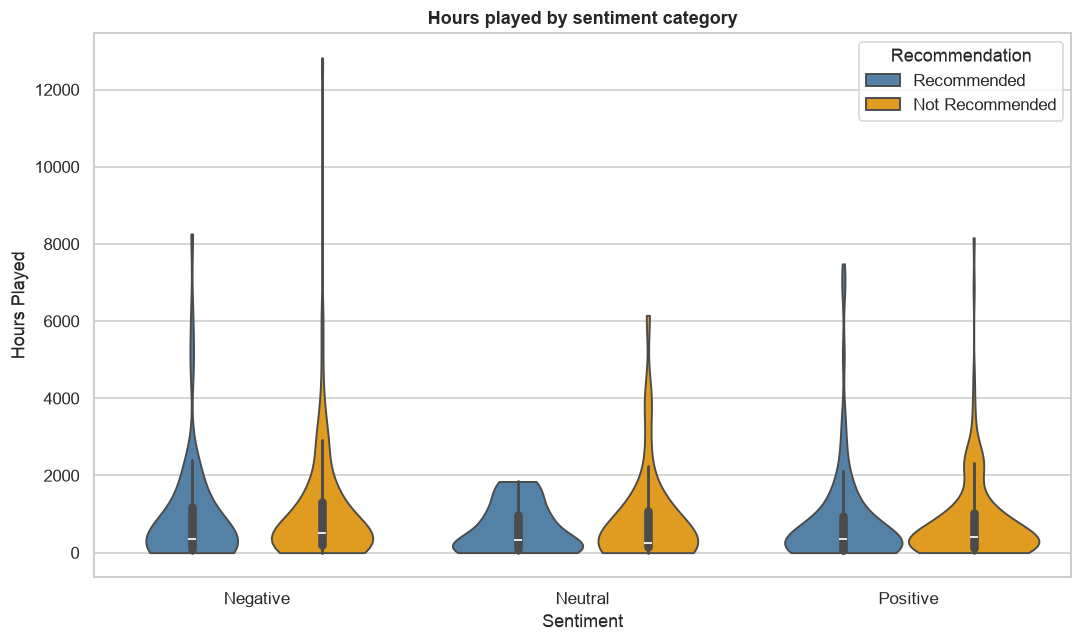

In [18]:
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=df_clean,
    x="sentiment_category",
    y="Hours Played",
    hue="Recommendation",
    order=CATEGORY_ORDER,
    hue_order=RECOMMENDATION_ORDER,
    palette=RECOMMENDATION_PALETTE,
    cut=0,
)
plt.title("Hours played by sentiment category")
plt.xlabel("Sentiment")
plt.tight_layout()
save_and_show("hours_played_by_sentiment")

### Correlations

In [19]:
# Pearson correlation of sentiment with engagement metrics, per period
correlations = pd.DataFrame(
    {
        period: {
            f"sentiment vs {metric}": group["sentiment_score"].corr(group[metric])
            for metric in METRICS
        }
        for period, group in df_clean.groupby("Period")
    }
)[PERIODS].round(4)
save_table(correlations, "correlations")
correlations

,Before,After
sentiment vs Hours Played,-0.0674,-0.0963
sentiment vs Helpful Votes,-0.1109,0.0795


## Saved outputs

Everything this notebook produced:

In [20]:
tables = sorted(p.name for p in OUTPUT_DIR.glob("*.csv"))
figures = sorted(p.name for p in FIGURES_DIR.glob("*.png"))
print(f"Tables in {OUTPUT_DIR.relative_to(PROJECT_ROOT)}/:", *tables, sep="\n  ")
print(
    f"\n{len(figures)} figures in {FIGURES_DIR.relative_to(PROJECT_ROOT)}/:", *figures, sep="\n  "
)

Tables in data/processed/PUBG/:
  PUBG_cleaned_processed_reviews.csv
  PUBG_correlations.csv
  PUBG_documents.csv
  PUBG_metadata.csv
  PUBG_sentiment.csv
  PUBG_sentiment_summary.csv
  PUBG_sentiment_vs_recommendation.csv
  PUBG_top_words_after.csv
  PUBG_top_words_all.csv
  PUBG_top_words_before.csv
  PUBG_yearly_sentiment.csv

27 figures in data/processed/PUBG/figures/:
  distribution_fit_after.png
  distribution_fit_before.png
  hours_played_by_sentiment.png
  sentiment_by_engagement.png
  sentiment_by_engagement_by_period.png
  sentiment_by_recommendation.png
  sentiment_categories.png
  sentiment_distribution.png
  sentiment_vs_helpful_votes_by_period.png
  sentiment_vs_hours_played_by_period.png
  sentiment_vs_metadata.png
  sentiment_vs_recommendation.png
  top_words_after.png
  top_words_all.png
  top_words_before.png
  wordcloud_2017.png
  wordcloud_2018.png
  wordcloud_2019.png
  wordcloud_2020.png
  wordcloud_2021.png
  wordcloud_2022.png
  wordcloud_2023.png
  wordcloud_20